# Prediction intervals for Italy's electricity demand

Compare 80% LightGBM quantile intervals with sequential conformal
intervals for day-ahead electricity demand.

- Features: calendar and past load.
- No weather or Terna forecast as model inputs.
- Forecast issuance: 10:00 Europe/Rome on the previous local day.
- Training and initial calibration: within the shared training period.
- Evaluation: the shared 2024 validation period.
- The 2025 test set remains reserved for the project leader.
- Calibration uses only residuals available at forecast issuance.

In [1]:
from pathlib import Path
import sys

# Find the repository root using the shared configuration file.
repo_root = next(
    (
        folder
        for folder in [Path.cwd(), *Path.cwd().parents]
        if (folder / "split_config.py").is_file()
    ),
    None,
)

if repo_root is None:
    raise FileNotFoundError(
        "split_config.py was not found. "
        "Open this notebook inside the project repository."
    )

# Allow Python to import modules from the repository root.
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

import split_config as config

print("Configuration file:", config.__file__)
print("Dataset path:", config.DATA_PATH)
print("Dataset exists:", config.DATA_PATH.is_file())
print("Forecast cutoff:", config.CUTOFF_HOUR, config.CUTOFF_TZ)
print("Allowed UTC lags:", config.SAFE_LAGS_HOURS)


Configuration file: /Users/marcohlovatskyi/Desktop/Bocconi/ML Projects/Energy/italy-electricity-load-forecasting/split_config.py
Dataset path: /Users/marcohlovatskyi/Desktop/Bocconi/ML Projects/Energy/italy-electricity-load-forecasting/data/processed/dataset_no_weather.csv
Dataset exists: True
Forecast cutoff: 10 Europe/Rome
Allowed UTC lags: (48, 168, 336)


In [2]:
# Load the shared dataset and apply the agreed chronological split.
df = config.load_data()
train, val = config.split(df)

print("Training rows:", len(train))
print(
    "Training local dates:",
    train.index.tz_convert(config.LOCAL_TZ).min(),
    "to",
    train.index.tz_convert(config.LOCAL_TZ).max(),
)

print("\nValidation rows:", len(val))
print(
    "Validation local dates:",
    val.index.tz_convert(config.LOCAL_TZ).min(),
    "to",
    val.index.tz_convert(config.LOCAL_TZ).max(),
)

print("\nAvailable columns:")
print(train.columns.tolist())

print("\nMissing training targets:", train[config.TARGET_COL].isna().sum())
print("Missing validation targets:", val[config.TARGET_COL].isna().sum())

Training rows: 17160
Training local dates: 2022-01-16 00:00:00+01:00 to 2023-12-31 23:00:00+01:00

Validation rows: 8784
Validation local dates: 2024-01-01 00:00:00+01:00 to 2024-12-31 23:00:00+01:00

Available columns:
['actual_load_mw', 'terna_forecast_mw', 'hour_local', 'day_of_week', 'month', 'year', 'is_weekend', 'is_holiday', 'is_summer', 'is_christmas_period']

Missing training targets: 0
Missing validation targets: 0


## Shared calendar and lag features

All LightGBM variants use the same calendar and lag features.

- Hour, weekday and month are encoded using sine and cosine.
- Calendar flags come from the shared dataset.
- Load lags are fixed UTC shifts of 48, 168 and 336 hours.
- Terna forecasts and contemporaneous actual load are excluded.
- Lag features are constructed before splitting to preserve past history.

In [3]:
# Keep the history needed for training and validation.
# Do not include timestamps after the validation period.
history = df.loc[:val.index.max()].copy()

# Create lag features using the shared availability checks.
data_with_lags = config.add_lags(history)

# Apply the shared split after constructing the lags.
train, val = config.split(data_with_lags)

lag_columns = [
    f"{config.TARGET_COL}_lag{hours}h"
    for hours in config.SAFE_LAGS_HOURS
]

print("Lag columns:", lag_columns)

print("\nMissing training lag values:")
print(train[lag_columns].isna().sum())

print("\nMissing validation lag values:")
print(val[lag_columns].isna().sum())

Lag columns: ['actual_load_mw_lag48h', 'actual_load_mw_lag168h', 'actual_load_mw_lag336h']

Missing training lag values:
actual_load_mw_lag48h     0
actual_load_mw_lag168h    0
actual_load_mw_lag336h    0
dtype: int64

Missing validation lag values:
actual_load_mw_lag48h     0
actual_load_mw_lag168h    0
actual_load_mw_lag336h    0
dtype: int64


In [4]:
import numpy as np
import pandas as pd

def build_calendar_lag_features(frame):
    """Build the shared no-weather features without fitting on data."""

    features = pd.DataFrame(index=frame.index)

    # Encode repeating calendar cycles.
    cycles = {
        "hour_local": (24, 0),
        "day_of_week": (7, 0),
        "month": (12, 1),
    }

    for column, (period, offset) in cycles.items():
        angle = 2 * np.pi * (frame[column] - offset) / period

        features[f"{column}_sin"] = np.sin(angle)
        features[f"{column}_cos"] = np.cos(angle)

    # Preserve the team's calendar flags, including its holiday definition.
    flag_columns = [
        "is_weekend",
        "is_holiday",
        "is_summer",
        "is_christmas_period",
    ]

    for column in flag_columns:
        features[column] = frame[column].astype(int)

    # Use all three lags allowed by the shared configuration.
    for hours in config.SAFE_LAGS_HOURS:
        column = f"{config.TARGET_COL}_lag{hours}h"
        features[column] = frame[column]

    return features

In [5]:
X_train = build_calendar_lag_features(train)
X_val = build_calendar_lag_features(val)

y_train = train[config.TARGET_COL].copy()
y_val = val[config.TARGET_COL].copy()

# Check the feature contract.
if X_train.columns.tolist() != X_val.columns.tolist():
    raise ValueError("Training and validation feature columns differ.")

if not X_train.index.equals(y_train.index):
    raise ValueError("Training features and targets are misaligned.")

if not X_val.index.equals(y_val.index):
    raise ValueError("Validation features and targets are misaligned.")

if not np.isfinite(X_train.to_numpy(dtype=float)).all():
    raise ValueError("Training features contain missing or infinite values.")

if not np.isfinite(X_val.to_numpy(dtype=float)).all():
    raise ValueError("Validation features contain missing or infinite values.")

for forbidden_column in [config.TARGET_COL, config.TERNA_COL]:
    if forbidden_column in X_train.columns:
        raise ValueError(f"Forbidden feature: {forbidden_column}")

print("Training feature matrix:", X_train.shape)
print("Validation feature matrix:", X_val.shape)
print("\nFeatures:")
print(X_train.columns.tolist())

display(X_train.head())

Training feature matrix: (17160, 13)
Validation feature matrix: (8784, 13)

Features:
['hour_local_sin', 'hour_local_cos', 'day_of_week_sin', 'day_of_week_cos', 'month_sin', 'month_cos', 'is_weekend', 'is_holiday', 'is_summer', 'is_christmas_period', 'actual_load_mw_lag48h', 'actual_load_mw_lag168h', 'actual_load_mw_lag336h']


,hour_local_sin,hour_local_cos,day_of_week_sin,day_of_week_cos,month_sin,month_cos,is_weekend,is_holiday,is_summer,is_christmas_period,actual_load_mw_lag48h,actual_load_mw_lag168h,actual_load_mw_lag336h
timestamp,,,,,,,,,,,,,
2022-01-15 23:00:00+00:00,0.000000,1.000000,-0.781831,0.62349,0.0,1.0,1,0,0,0,29019.0,24397.0,20428.0
2022-01-16 00:00:00+00:00,0.258819,0.965926,-0.781831,0.62349,0.0,1.0,1,0,0,0,27210.0,22471.0,18989.0
2022-01-16 01:00:00+00:00,0.500000,0.866025,-0.781831,0.62349,0.0,1.0,1,0,0,0,26351.0,21364.0,18083.0
2022-01-16 02:00:00+00:00,0.707107,0.707107,-0.781831,0.62349,0.0,1.0,1,0,0,0,26136.0,20827.0,17740.0
2022-01-16 03:00:00+00:00,0.866025,0.500000,-0.781831,0.62349,0.0,1.0,1,0,0,0,26400.0,20920.0,17737.0


In [6]:
%pip install lightgbm scikit-learn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 10.2 MB/s  0:00:00
Note: you may need to restart the kernel to use updated packages.


In [7]:
import lightgbm as lgb
import sklearn

print("LightGBM version:", lgb.__version__)
print("scikit-learn version:", sklearn.__version__)

LightGBM version: 4.7.0
scikit-learn version: 1.9.0


## Hyperparameter selection within the training period

Use four expanding chronological folds from split_config.py.

Each fold trains on earlier local days and evaluates on later local days.
Training targets must be available before the first forecast issuance
in the evaluation block, using the shared publication-delay assumption.

The 2024 validation period is excluded from hyperparameter selection.

In [8]:
# Generate expanding folds using the shared local-day rules.
fold_days = config.chronological_local_day_folds(
    train.index,
    n_splits=4,
)

prepared_folds = []
fold_summary = []

for fold_number, (fit_days, evaluation_days) in enumerate(
    fold_days,
    start=1,
):
    fit_rows = config.rows_on_local_days(train, fit_days)
    evaluation_rows = config.rows_on_local_days(train, evaluation_days)

    # Find the issuance time for the first day being predicted.
    first_cutoff = config.cutoff_timestamps(
        evaluation_rows.index[:1]
    )[0].tz_convert("UTC")

    # A training target must already be available at that cutoff.
    target_available_at = fit_rows.index + pd.Timedelta(
        hours=config.PUBLICATION_LAG_HOURS
    )

    available_mask = target_available_at <= first_cutoff
    eligible_fit_rows = fit_rows.loc[available_mask]

    if eligible_fit_rows.empty or evaluation_rows.empty:
        raise ValueError("A fold has no training or evaluation rows.")

    prepared_folds.append({
        "fold": fold_number,
        "train_index": eligible_fit_rows.index,
        "evaluation_index": evaluation_rows.index,
    })

    fold_summary.append({
        "fold": fold_number,
        "train_start_local": eligible_fit_rows.index.min().tz_convert(
            config.LOCAL_TZ
        ),
        "train_end_local": eligible_fit_rows.index.max().tz_convert(
            config.LOCAL_TZ
        ),
        "evaluation_start_local": evaluation_rows.index.min().tz_convert(
            config.LOCAL_TZ
        ),
        "evaluation_end_local": evaluation_rows.index.max().tz_convert(
            config.LOCAL_TZ
        ),
        "train_rows": len(eligible_fit_rows),
        "evaluation_rows": len(evaluation_rows),
        "excluded_unavailable_targets": int((~available_mask).sum()),
    })

fold_summary_df = pd.DataFrame(fold_summary)

display(fold_summary_df)

,fold,train_start_local,train_end_local,evaluation_start_local,evaluation_end_local,train_rows,evaluation_rows,excluded_unavailable_targets
0,1,2022-01-16 00:00:00+01:00,2022-06-07 08:00:00+02:00,2022-06-08 00:00:00+02:00,2022-10-28 23:00:00+02:00,3416,3432,15
1,2,2022-01-16 00:00:00+01:00,2022-10-28 08:00:00+02:00,2022-10-29 00:00:00+02:00,2023-03-20 23:00:00+01:00,6848,3433,15
2,3,2022-01-16 00:00:00+01:00,2023-03-20 08:00:00+01:00,2023-03-21 00:00:00+01:00,2023-08-10 23:00:00+02:00,10281,3431,15
3,4,2022-01-16 00:00:00+01:00,2023-08-10 08:00:00+02:00,2023-08-11 00:00:00+02:00,2023-12-31 23:00:00+01:00,13712,3433,15


In [10]:
from sklearn.model_selection import ParameterGrid

# Use the same search space for all three point-model variants.
parameter_candidates = list(ParameterGrid({
    "n_estimators": [200, 500],
    "num_leaves": [7, 15, 31],
}))

fixed_parameters = {
    "objective": "regression",
    "learning_rate": 0.05,
    "min_child_samples": 30,
    "random_state": 42,
    "n_jobs": 2,
    "verbosity": -1,
    "deterministic": True,
    "force_col_wise": True,
}

print("Parameter combinations:", len(parameter_candidates))
print("Total fits:", len(parameter_candidates) * len(prepared_folds))

display(pd.DataFrame(parameter_candidates))

Parameter combinations: 6
Total fits: 24


,n_estimators,num_leaves
0,200,7
1,200,15
2,200,31
3,500,7
4,500,15
5,500,31


In [11]:
cv_records = []

for candidate_id, parameters in enumerate(parameter_candidates, start=1):
    for fold in prepared_folds:
        fit_index = fold["train_index"]
        evaluation_index = fold["evaluation_index"]

        # Create a new model for every candidate and fold.
        model = lgb.LGBMRegressor(
            **fixed_parameters,
            **parameters,
        )

        model.fit(
            X_train.loc[fit_index],
            y_train.loc[fit_index],
        )

        predictions = model.predict(
            X_train.loc[evaluation_index]
        )

        scores = config.metrics(
            y_train.loc[evaluation_index],
            predictions,
        )

        cv_records.append({
            "candidate_id": candidate_id,
            "fold": fold["fold"],
            **parameters,
            "n": scores["n"],
            "MAE": scores["MAE"],
            "RMSE": scores["RMSE"],
        })

        print(
            f"Candidate {candidate_id}/{len(parameter_candidates)} "
            f"| Fold {fold['fold']} "
            f"| MAE: {scores['MAE']:.1f} MW",
            flush=True,
        )

cv_results = pd.DataFrame(cv_records)

Candidate 1/6 | Fold 1 | MAE: 2238.8 MW
Candidate 1/6 | Fold 2 | MAE: 1620.0 MW
Candidate 1/6 | Fold 3 | MAE: 1767.4 MW
Candidate 1/6 | Fold 4 | MAE: 1338.4 MW
Candidate 2/6 | Fold 1 | MAE: 2240.6 MW
Candidate 2/6 | Fold 2 | MAE: 1536.0 MW
Candidate 2/6 | Fold 3 | MAE: 1642.8 MW
Candidate 2/6 | Fold 4 | MAE: 1214.7 MW
Candidate 3/6 | Fold 1 | MAE: 2210.4 MW
Candidate 3/6 | Fold 2 | MAE: 1484.5 MW
Candidate 3/6 | Fold 3 | MAE: 1563.9 MW
Candidate 3/6 | Fold 4 | MAE: 1143.8 MW
Candidate 4/6 | Fold 1 | MAE: 2232.1 MW
Candidate 4/6 | Fold 2 | MAE: 1458.0 MW
Candidate 4/6 | Fold 3 | MAE: 1633.9 MW
Candidate 4/6 | Fold 4 | MAE: 1191.4 MW
Candidate 5/6 | Fold 1 | MAE: 2219.4 MW
Candidate 5/6 | Fold 2 | MAE: 1429.4 MW
Candidate 5/6 | Fold 3 | MAE: 1528.7 MW
Candidate 5/6 | Fold 4 | MAE: 1110.3 MW
Candidate 6/6 | Fold 1 | MAE: 2204.3 MW
Candidate 6/6 | Fold 2 | MAE: 1412.1 MW
Candidate 6/6 | Fold 3 | MAE: 1488.2 MW
Candidate 6/6 | Fold 4 | MAE: 1080.4 MW


In [12]:
candidate_summaries = []

for candidate_id, group in cv_results.groupby("candidate_id"):
    total_n = int(group["n"].sum())

    # Pool errors across folds, accounting for different fold sizes.
    pooled_mae = (group["MAE"] * group["n"]).sum() / total_n
    pooled_rmse = np.sqrt(
        (group["RMSE"] ** 2 * group["n"]).sum() / total_n
    )

    candidate_summaries.append({
        "candidate_id": int(candidate_id),
        **parameter_candidates[int(candidate_id) - 1],
        "n": total_n,
        "CV_MAE_MW": pooled_mae,
        "CV_RMSE_MW": pooled_rmse,
    })

cv_summary = (
    pd.DataFrame(candidate_summaries)
    .sort_values(["CV_MAE_MW", "candidate_id"])
    .reset_index(drop=True)
)

best_candidate_id = int(cv_summary.loc[0, "candidate_id"])
best_params_noweather = parameter_candidates[
    best_candidate_id - 1
].copy()

display(cv_summary)
print("Selected no-weather parameters:", best_params_noweather)

,candidate_id,n_estimators,num_leaves,n,CV_MAE_MW,CV_RMSE_MW
0,6,500,31,13729,1546.196607,2202.652739
1,5,500,15,13729,1571.914285,2217.470964
2,3,200,31,13729,1600.600763,2273.136138
3,4,500,7,13729,1628.822962,2286.771366
4,2,200,15,13729,1658.482805,2339.080392
5,1,200,7,13729,1741.124320,2446.805350


Selected no-weather parameters: {'n_estimators': 500, 'num_leaves': 31}


## No-weather model: evaluation on the 2024 holdout

The selected configuration uses 500 trees and 31 leaves per tree,
chosen by pooled MAE across four chronological training folds.

Hyperparameters are now fixed for this experiment.
The model is trained using only targets available at the first
2024 forecast cutoff and remains fixed throughout validation.

Past-load features update as observations become available.
The 2024 results are not used to retune this model.

In [13]:
# Determine when the first validation forecast would be issued.
first_validation_cutoff = config.cutoff_timestamps(
    val.index[:1]
)[0].tz_convert("UTC")

# Apply the shared publication-delay assumption to training targets.
training_target_available_at = train.index + pd.Timedelta(
    hours=config.PUBLICATION_LAG_HOURS
)

final_fit_mask = (
    training_target_available_at <= first_validation_cutoff
)
final_fit_index = train.index[final_fit_mask]

print(
    "First validation cutoff:",
    first_validation_cutoff.tz_convert(config.LOCAL_TZ),
)
print("Rows used for fitting:", len(final_fit_index))
print("Rows excluded at the boundary:", int((~final_fit_mask).sum()))
print(
    "Last training target:",
    final_fit_index.max().tz_convert(config.LOCAL_TZ),
)

First validation cutoff: 2023-12-31 10:00:00+01:00
Rows used for fitting: 17145
Rows excluded at the boundary: 15
Last training target: 2023-12-31 08:00:00+01:00


In [14]:
# Train a new model with the selected hyperparameters.
model_noweather = lgb.LGBMRegressor(
    **fixed_parameters,
    **best_params_noweather,
)

model_noweather.fit(
    X_train.loc[final_fit_index],
    y_train.loc[final_fit_index],
)

# Generate predictions for every validation hour.
y_pred_noweather = pd.Series(
    model_noweather.predict(X_val),
    index=X_val.index,
    name="y_pred",
)

# Evaluate using the shared metrics.
validation_scores_noweather = config.metrics(
    y_val,
    y_pred_noweather,
)

display(pd.DataFrame([{
    "model": "lgbm_noweather",
    **validation_scores_noweather,
}]))

,model,n,MAE,RMSE
0,lgbm_noweather,8784,1136.985662,1623.176669


In [15]:
predictions_noweather = pd.DataFrame({
    "timestamp": y_val.index,
    "y_true": y_val.to_numpy(),
    "y_pred": y_pred_noweather.to_numpy(),
    "model": "lgbm_noweather",
})

print("Prediction rows:", len(predictions_noweather))
display(predictions_noweather.head())

Prediction rows: 8784


,timestamp,y_true,y_pred,model
0,2023-12-31 23:00:00+00:00,20694.0,19718.698119,lgbm_noweather
1,2024-01-01 00:00:00+00:00,19910.0,18749.619306,lgbm_noweather
2,2024-01-01 01:00:00+00:00,18833.0,17687.250662,lgbm_noweather
3,2024-01-01 02:00:00+00:00,17878.0,17520.588711,lgbm_noweather
4,2024-01-01 03:00:00+00:00,17312.0,17539.203443,lgbm_noweather


In [16]:
prediction_dir = repo_root / "predictions"
prediction_dir.mkdir(parents=True, exist_ok=True)

prediction_path = prediction_dir / "lgbm_noweather.csv"

# Format UTC timestamps without changing the working table.
prediction_export = predictions_noweather.copy()
prediction_export["timestamp"] = (
    prediction_export["timestamp"]
    .dt.strftime("%Y-%m-%dT%H:%M:%SZ")
)

# This file is regenerated when this cell is rerun.
prediction_export.to_csv(prediction_path, index=False)

# Validate the saved file using the team's shared checks.
checked_predictions = config.check_predictions(
    prediction_path,
    config.validation_index(df),
    reference_y=df[config.TARGET_COL],
)

print("Saved:", prediction_path)
print("Validated prediction rows:", len(checked_predictions))

Saved: /Users/marcohlovatskyi/Desktop/Bocconi/ML Projects/Energy/italy-electricity-load-forecasting/predictions/lgbm_noweather.csv
Validated prediction rows: 8784


## Observed-weather model — upper-bound experiment

Add the six observed temperature series to the shared calendar and
lag features. Use the same chronological folds and hyperparameter
search as the no-weather model.

Observed target-hour weather is not available at forecast issuance.
This experiment is labelled upper bound and is not operational.

In [17]:
weather_observed = config.load_observed_weather()

# Keep only the period needed for training and validation.
weather_observed = weather_observed.loc[
    history.index.min():val.index.max()
].copy()

if weather_observed.index.has_duplicates:
    raise ValueError("Observed weather contains duplicate timestamps.")

temperature_columns = list(config.OBSERVED_TEMP_COLUMNS)

# Join by UTC timestamp, preserving all electricity rows.
X_train_obs = X_train.join(
    weather_observed[temperature_columns],
    how="left",
    validate="one_to_one",
)

X_val_obs = X_val.join(
    weather_observed[temperature_columns],
    how="left",
    validate="one_to_one",
)

print("Missing training temperatures:")
print(X_train_obs[temperature_columns].isna().sum())

print("\nMissing validation temperatures:")
print(X_val_obs[temperature_columns].isna().sum())

print("\nTraining feature matrix:", X_train_obs.shape)
print("Validation feature matrix:", X_val_obs.shape)

if not np.isfinite(
    X_train_obs[temperature_columns].to_numpy(dtype=float)
).all():
    raise ValueError("Investigate missing or infinite training temperatures.")

if not np.isfinite(
    X_val_obs[temperature_columns].to_numpy(dtype=float)
).all():
    raise ValueError("Investigate missing or infinite validation temperatures.")

Missing training temperatures:
temp_milano_c     0
temp_torino_c     0
temp_bologna_c    0
temp_roma_c       0
temp_napoli_c     0
temp_palermo_c    0
dtype: int64

Missing validation temperatures:
temp_milano_c     0
temp_torino_c     0
temp_bologna_c    0
temp_roma_c       0
temp_napoli_c     0
temp_palermo_c    0
dtype: int64

Training feature matrix: (17160, 19)
Validation feature matrix: (8784, 19)


In [18]:
cv_records_obs = []

for candidate_id, parameters in enumerate(parameter_candidates, start=1):
    for fold in prepared_folds:
        fit_index = fold["train_index"]
        evaluation_index = fold["evaluation_index"]

        model = lgb.LGBMRegressor(
            **fixed_parameters,
            **parameters,
        )

        model.fit(
            X_train_obs.loc[fit_index],
            y_train.loc[fit_index],
        )

        predictions = model.predict(
            X_train_obs.loc[evaluation_index]
        )

        scores = config.metrics(
            y_train.loc[evaluation_index],
            predictions,
        )

        cv_records_obs.append({
            "candidate_id": candidate_id,
            "fold": fold["fold"],
            **parameters,
            "n": scores["n"],
            "MAE": scores["MAE"],
            "RMSE": scores["RMSE"],
        })

        print(
            f"Upper bound | Candidate {candidate_id}/"
            f"{len(parameter_candidates)} "
            f"| Fold {fold['fold']} "
            f"| MAE: {scores['MAE']:.1f} MW",
            flush=True,
        )

cv_results_obs = pd.DataFrame(cv_records_obs)

Upper bound | Candidate 1/6 | Fold 1 | MAE: 2072.2 MW
Upper bound | Candidate 1/6 | Fold 2 | MAE: 1631.9 MW
Upper bound | Candidate 1/6 | Fold 3 | MAE: 1641.2 MW
Upper bound | Candidate 1/6 | Fold 4 | MAE: 1296.6 MW
Upper bound | Candidate 2/6 | Fold 1 | MAE: 2085.4 MW
Upper bound | Candidate 2/6 | Fold 2 | MAE: 1511.5 MW
Upper bound | Candidate 2/6 | Fold 3 | MAE: 1472.5 MW
Upper bound | Candidate 2/6 | Fold 4 | MAE: 1146.1 MW
Upper bound | Candidate 3/6 | Fold 1 | MAE: 2100.0 MW
Upper bound | Candidate 3/6 | Fold 2 | MAE: 1442.9 MW
Upper bound | Candidate 3/6 | Fold 3 | MAE: 1338.5 MW
Upper bound | Candidate 3/6 | Fold 4 | MAE: 1062.1 MW
Upper bound | Candidate 4/6 | Fold 1 | MAE: 2088.4 MW
Upper bound | Candidate 4/6 | Fold 2 | MAE: 1454.1 MW
Upper bound | Candidate 4/6 | Fold 3 | MAE: 1457.2 MW
Upper bound | Candidate 4/6 | Fold 4 | MAE: 1082.7 MW
Upper bound | Candidate 5/6 | Fold 1 | MAE: 2061.6 MW
Upper bound | Candidate 5/6 | Fold 2 | MAE: 1368.5 MW
Upper bound | Candidate 5/6 

In [19]:
candidate_summaries_obs = []

for candidate_id, group in cv_results_obs.groupby("candidate_id"):
    total_n = int(group["n"].sum())

    pooled_mae = (group["MAE"] * group["n"]).sum() / total_n
    pooled_rmse = np.sqrt(
        (group["RMSE"] ** 2 * group["n"]).sum() / total_n
    )

    candidate_summaries_obs.append({
        "candidate_id": int(candidate_id),
        **parameter_candidates[int(candidate_id) - 1],
        "n": total_n,
        "CV_MAE_MW": pooled_mae,
        "CV_RMSE_MW": pooled_rmse,
    })

cv_summary_obs = (
    pd.DataFrame(candidate_summaries_obs)
    .sort_values(["CV_MAE_MW", "candidate_id"])
    .reset_index(drop=True)
)

best_candidate_id_obs = int(cv_summary_obs.loc[0, "candidate_id"])
best_params_obs = parameter_candidates[
    best_candidate_id_obs - 1
].copy()

display(cv_summary_obs)
print("Selected upper-bound parameters:", best_params_obs)

,candidate_id,n_estimators,num_leaves,n,CV_MAE_MW,CV_RMSE_MW
0,6,500,31,13729,1428.056476,2100.328579
1,5,500,15,13729,1446.797905,2099.300794
2,3,200,31,13729,1485.849057,2164.663520
3,4,500,7,13729,1520.547955,2159.533708
4,2,200,15,13729,1553.845873,2228.039458
5,1,200,7,13729,1660.416047,2338.191667


Selected upper-bound parameters: {'n_estimators': 500, 'num_leaves': 31}


In [20]:
# Fit using the same eligible training rows as the no-weather model.
model_obs = lgb.LGBMRegressor(
    **fixed_parameters,
    **best_params_obs,
)

model_obs.fit(
    X_train_obs.loc[final_fit_index],
    y_train.loc[final_fit_index],
)

y_pred_obs = pd.Series(
    model_obs.predict(X_val_obs),
    index=X_val_obs.index,
    name="y_pred",
)

validation_scores_obs = config.metrics(y_val, y_pred_obs)

comparison_models = pd.DataFrame([
    {
        "model": "lgbm_noweather",
        "experiment": "no weather",
        **validation_scores_noweather,
    },
    {
        "model": "lgbm_obs_upper_bound",
        "experiment": "observed weather — upper bound",
        **validation_scores_obs,
    },
])

display(comparison_models)

,model,experiment,n,MAE,RMSE
0,lgbm_noweather,no weather,8784,1136.985662,1623.176669
1,lgbm_obs_upper_bound,observed weather — upper bound,8784,1046.461602,1524.114118


In [21]:
predictions_obs = pd.DataFrame({
    "timestamp": y_val.index,
    "y_true": y_val.to_numpy(),
    "y_pred": y_pred_obs.to_numpy(),
    "model": "lgbm_obs_upper_bound",
})

prediction_export_obs = predictions_obs.copy()
prediction_export_obs["timestamp"] = (
    prediction_export_obs["timestamp"]
    .dt.strftime("%Y-%m-%dT%H:%M:%SZ")
)

prediction_path_obs = prediction_dir / "lgbm_obs_upper_bound.csv"

# Regenerate this model's output when the cell is rerun.
prediction_export_obs.to_csv(prediction_path_obs, index=False)

checked_predictions_obs = config.check_predictions(
    prediction_path_obs,
    config.validation_index(df),
    reference_y=df[config.TARGET_COL],
)

print("Saved:", prediction_path_obs)
print("Validated prediction rows:", len(checked_predictions_obs))

Saved: /Users/marcohlovatskyi/Desktop/Bocconi/ML Projects/Energy/italy-electricity-load-forecasting/predictions/lgbm_obs_upper_bound.csv
Validated prediction rows: 8784


In [22]:
results_dir = repo_root / "notebooks" / "marco" / "results"
results_dir.mkdir(parents=True, exist_ok=True)

cv_results.to_csv(
    results_dir / "lgbm_noweather_cv_folds.csv",
    index=False,
)
cv_summary.to_csv(
    results_dir / "lgbm_noweather_cv_summary.csv",
    index=False,
)

cv_results_obs.to_csv(
    results_dir / "lgbm_obs_upper_bound_cv_folds.csv",
    index=False,
)
cv_summary_obs.to_csv(
    results_dir / "lgbm_obs_upper_bound_cv_summary.csv",
    index=False,
)

comparison_models.to_csv(
    results_dir / "lgbm_validation_comparison.csv",
    index=False,
)

print("Results saved in:", results_dir)

Results saved in: /Users/marcohlovatskyi/Desktop/Bocconi/ML Projects/Energy/italy-electricity-load-forecasting/notebooks/marco/results


In [23]:
forecast_file_exists = config.WEATHER_FORECAST_PATH.is_file()
forecast_verified = config.FORECAST_COVERAGE_VERIFIED

print("Forecast weather file:", config.WEATHER_FORECAST_PATH)
print("File exists:", forecast_file_exists)
print("Coverage verified:", forecast_verified)

if forecast_file_exists and forecast_verified:
    print("Forecast-weather experiment can proceed to data inspection.")
else:
    print(
        "Forecast-weather experiment is blocked by the shared protocol. "
        "Continue with no-weather analysis and prediction intervals."
    )

Forecast weather file: /Users/marcohlovatskyi/Desktop/Bocconi/ML Projects/Energy/italy-electricity-load-forecasting/data/processed/weather_forecast_gfs.csv
File exists: False
Coverage verified: False
Forecast-weather experiment is blocked by the shared protocol. Continue with no-weather analysis and prediction intervals.


## Validation comparison against shared baselines

Compare the two LightGBM variants with seasonal naive,
seasonal average and Terna on the 2024 validation period.

Report both all available hours and the common timestamp intersection.
The seasonal naive baseline can be undefined around daylight saving time.

Observed-weather results remain labelled upper bound.
Terna's historical forecast vintage is not yet verified.

In [24]:
baseline_naive = config.seasonal_naive(history).reindex(val.index)

# Estimate the seasonal profile only from targets available at issuance.
baseline_average = config.seasonal_average_prediction(
    train.loc[final_fit_index],
    val,
)

baseline_terna = val[config.TERNA_COL].copy()

evaluation_predictions = pd.DataFrame(
    {
        "seasonal_naive": baseline_naive,
        "seasonal_avg": baseline_average,
        "terna": baseline_terna,
        "lgbm_noweather": y_pred_noweather,
        "lgbm_obs_upper_bound": y_pred_obs,
    },
    index=val.index,
)

# Only the documented seasonal-naive timestamps may be missing.
allowed_naive_missing = config.seasonal_naive_undefined(val.index)

for model_name in evaluation_predictions.columns:
    values = evaluation_predictions[model_name]

    if values.isin([float("inf"), float("-inf")]).any():
        raise ValueError(f"Infinite predictions: {model_name}")

    missing_index = values.index[values.isna()]

    if model_name == "seasonal_naive":
        if (
            len(missing_index.difference(allowed_naive_missing))
            or len(allowed_naive_missing.difference(missing_index))
        ):
            raise ValueError("Unexpected seasonal-naive missing timestamps.")
    elif len(missing_index):
        raise ValueError(f"Unexpected missing predictions: {model_name}")

print("Missing predictions by model:")
print(evaluation_predictions.isna().sum())

Missing predictions by model:
seasonal_naive          1
seasonal_avg            0
terna                   0
lgbm_noweather          0
lgbm_obs_upper_bound    0
dtype: int64


In [25]:
comparison_records = []

# Hours where every model has a prediction.
common_mask = evaluation_predictions.notna().all(axis=1)

for model_name in evaluation_predictions.columns:
    available_mask = evaluation_predictions[model_name].notna()

    for scope, mask in [
        ("all_available", available_mask),
        ("common_hours", common_mask),
    ]:
        scores = config.metrics(
            y_val.loc[mask],
            evaluation_predictions.loc[mask, model_name],
        )

        comparison_records.append({
            "model": model_name,
            "scope": scope,
            **scores,
        })

baseline_comparison = pd.DataFrame(comparison_records)

print("Comparison on all available hours:")
display(
    baseline_comparison.loc[
        baseline_comparison["scope"] == "all_available"
    ].sort_values("MAE")
)

print("\nComparison on common hours:")
display(
    baseline_comparison.loc[
        baseline_comparison["scope"] == "common_hours"
    ].sort_values("MAE")
)

baseline_comparison.to_csv(
    results_dir / "validation_baseline_comparison.csv",
    index=False,
)

Comparison on all available hours:


,model,scope,n,MAE,RMSE
4,terna,all_available,8784,603.931125,816.299599
8,lgbm_obs_upper_bound,all_available,8784,1046.461602,1524.114118
6,lgbm_noweather,all_available,8784,1136.985662,1623.176669
0,seasonal_naive,all_available,8783,1975.138335,3177.185755
2,seasonal_avg,all_available,8784,2718.712959,3653.984202



Comparison on common hours:


,model,scope,n,MAE,RMSE
5,terna,common_hours,8783,603.980758,816.344100
9,lgbm_obs_upper_bound,common_hours,8783,1046.550603,1524.198262
7,lgbm_noweather,common_hours,8783,1137.111129,1623.269028
1,seasonal_naive,common_hours,8783,1975.138335,3177.185755
3,seasonal_avg,common_hours,8783,2718.834115,3654.149560


In [26]:
# Extract feature importance from the fitted no-weather model.
booster = model_noweather.booster_

feature_importance = pd.DataFrame({
    "feature": booster.feature_name(),
    "gain": booster.feature_importance(importance_type="gain"),
    "split_count": booster.feature_importance(importance_type="split"),
})

total_gain = feature_importance["gain"].sum()

feature_importance["gain_pct"] = (
    100 * feature_importance["gain"] / total_gain
    if total_gain > 0
    else 0.0
)

feature_importance = (
    feature_importance
    .sort_values("gain", ascending=False)
    .reset_index(drop=True)
)

feature_importance.to_csv(
    results_dir / "lgbm_noweather_feature_importance.csv",
    index=False,
)

display(feature_importance)

,feature,gain,split_count,gain_pct
0,actual_load_mw_lag168h,7.177554e+12,2875,81.446785
1,actual_load_mw_lag48h,3.963789e+11,2841,4.497881
2,is_holiday,3.671269e+11,344,4.165946
3,actual_load_mw_lag336h,1.995295e+11,2224,2.264147
4,day_of_week_sin,1.914772e+11,1128,2.172774
5,month_sin,1.133864e+11,1185,1.286644
6,hour_local_cos,9.700637e+10,1169,1.100773
7,is_christmas_period,8.614718e+10,180,0.977549
8,month_cos,6.876882e+10,1190,0.780349
9,day_of_week_cos,6.660061e+10,706,0.755746


## Quantile-regression intervals: 80% nominal coverage

Train two no-weather LightGBM models with quantile objectives:
alpha = 0.10 and alpha = 0.90.

Use the same features and eligible training rows as the point model.
Reuse the hyperparameters selected by point-forecast training CV;
no separate quantile-specific tuning is performed.

Evaluate pinball loss, empirical coverage and mean interval width
on the 2024 holdout.

If predicted quantiles cross, order the two endpoints before computing
interval metrics and report the number of crossings.

In [27]:
# Define the interval before inspecting its validation performance.
quantile_low = 0.10
quantile_high = 0.90
nominal_coverage = 0.80

# Copy the point-model settings and replace the training objective.
quantile_parameters = {
    **fixed_parameters,
    **best_params_noweather,
}
quantile_parameters["objective"] = "quantile"

model_quantile_low = lgb.LGBMRegressor(
    **quantile_parameters,
    alpha=quantile_low,
)

model_quantile_high = lgb.LGBMRegressor(
    **quantile_parameters,
    alpha=quantile_high,
)

model_quantile_low.fit(
    X_train.loc[final_fit_index],
    y_train.loc[final_fit_index],
)

model_quantile_high.fit(
    X_train.loc[final_fit_index],
    y_train.loc[final_fit_index],
)

print("Both quantile models fitted.")

Both quantile models fitted.


In [28]:
q10_raw = model_quantile_low.predict(X_val)
q90_raw = model_quantile_high.predict(X_val)

if not (
    np.isfinite(q10_raw).all()
    and np.isfinite(q90_raw).all()
):
    raise ValueError("Quantile predictions contain missing or infinite values.")

# Independently trained models can occasionally produce crossed quantiles.
crossed = q10_raw > q90_raw

# Apply the endpoint-ordering rule specified before evaluation.
interval_low = np.minimum(q10_raw, q90_raw)
interval_high = np.maximum(q10_raw, q90_raw)

quantile_predictions = pd.DataFrame({
    "timestamp": y_val.index,
    "y_true": y_val.to_numpy(),
    "y_pred": y_pred_noweather.to_numpy(),
    "model": "lgbm_quantile80_noweather",
    "y_lo": interval_low,
    "y_hi": interval_high,
    "nominal_coverage": nominal_coverage,
})

print("Crossed quantiles:", int(crossed.sum()))
print("Prediction rows:", len(quantile_predictions))

display(quantile_predictions.head())

Crossed quantiles: 17
Prediction rows: 8784


,timestamp,y_true,y_pred,model,y_lo,y_hi,nominal_coverage
0,2023-12-31 23:00:00+00:00,20694.0,19718.698119,lgbm_quantile80_noweather,19248.776330,20635.229670,0.8
1,2024-01-01 00:00:00+00:00,19910.0,18749.619306,lgbm_quantile80_noweather,17712.553187,19801.265263,0.8
2,2024-01-01 01:00:00+00:00,18833.0,17687.250662,lgbm_quantile80_noweather,17379.000135,18542.878522,0.8
3,2024-01-01 02:00:00+00:00,17878.0,17520.588711,lgbm_quantile80_noweather,17102.433922,18385.423638,0.8
4,2024-01-01 03:00:00+00:00,17312.0,17539.203443,lgbm_quantile80_noweather,17032.153006,18174.950233,0.8


In [29]:
from sklearn.metrics import mean_pinball_loss

truth = y_val.to_numpy()

inside_interval = (
    (truth >= interval_low)
    & (truth <= interval_high)
)

quantile_interval_metrics = pd.DataFrame([{
    "model": "lgbm_quantile80_noweather",
    "n": len(truth),
    "nominal_coverage": nominal_coverage,
    "empirical_coverage": inside_interval.mean(),
    "mean_width_mw": (interval_high - interval_low).mean(),
    "below_interval_rate": (truth < interval_low).mean(),
    "above_interval_rate": (truth > interval_high).mean(),
    "pinball_q10_raw": mean_pinball_loss(
        truth, q10_raw, alpha=quantile_low
    ),
    "pinball_q90_raw": mean_pinball_loss(
        truth, q90_raw, alpha=quantile_high
    ),
    "crossed_quantiles": int(crossed.sum()),
}])

display(quantile_interval_metrics.T)

,0
model,lgbm_quantile80_noweather
n,8784
nominal_coverage,0.8
empirical_coverage,0.663479
mean_width_mw,2722.702865
below_interval_rate,0.167464
above_interval_rate,0.169057
pinball_q10_raw,308.570374
pinball_q90_raw,295.356203
crossed_quantiles,17


In [30]:
# Validate interval-specific fields before exporting.
interval_columns = ["y_lo", "y_hi", "nominal_coverage"]

if not np.isfinite(
    quantile_predictions[interval_columns].to_numpy(dtype=float)
).all():
    raise ValueError("Interval fields contain missing or infinite values.")

if (
    quantile_predictions["y_lo"] > quantile_predictions["y_hi"]
).any():
    raise ValueError("Some interval endpoints are not ordered.")

if not np.allclose(
    quantile_predictions["nominal_coverage"], 0.80
):
    raise ValueError("Unexpected nominal coverage.")

quantile_export = quantile_predictions.copy()
quantile_export["timestamp"] = (
    quantile_export["timestamp"].dt.strftime("%Y-%m-%dT%H:%M:%SZ")
)

quantile_path = prediction_dir / "lgbm_quantile80_noweather.csv"
quantile_export.to_csv(quantile_path, index=False)

checked_quantiles = config.check_predictions(
    quantile_path,
    config.validation_index(df),
    reference_y=df[config.TARGET_COL],
)

quantile_interval_metrics.to_csv(
    results_dir / "lgbm_quantile80_noweather_metrics.csv",
    index=False,
)

print("Saved:", quantile_path)
print("Validated rows:", len(checked_quantiles))

Saved: /Users/marcohlovatskyi/Desktop/Bocconi/ML Projects/Energy/italy-electricity-load-forecasting/predictions/lgbm_quantile80_noweather.csv
Validated rows: 8784


## Sequential conformal: development and initial calibration

Reserve the final three local calendar months of the shared training
period for initial calibration.

Select hyperparameters again using only the earlier development period.
Neither model fitting nor hyperparameter selection uses calibration targets.

Calibration scores will be absolute out-of-sample prediction errors.
During validation, scores become eligible only after their target's
publication time under the shared two-hour delay assumption.

Keep nominal coverage at 80%. Specify the sequential update rule before
evaluating its 2024 coverage. Temporal dependence means that standard
exchangeable-data coverage guarantees cannot be assumed.

In [31]:
# Reserve the last three calendar months of the shared training period.
validation_start_local = config.local_midnight(val.index).min()
calibration_start_local = (
    validation_start_local - pd.DateOffset(months=3)
)

training_local_days = config.local_midnight(train.index)

development_rows = train.loc[
    training_local_days < calibration_start_local
].copy()

calibration_rows = train.loc[
    training_local_days >= calibration_start_local
].copy()

# The model must be fitted before the first calibration forecast.
first_calibration_cutoff = config.cutoff_timestamps(
    calibration_rows.index[:1]
)[0].tz_convert("UTC")

development_available_at = (
    development_rows.index
    + pd.Timedelta(hours=config.PUBLICATION_LAG_HOURS)
)

conformal_fit_index = development_rows.index[
    development_available_at <= first_calibration_cutoff
]

if len(conformal_fit_index.intersection(calibration_rows.index)):
    raise ValueError("Model-fitting and calibration rows overlap.")

print("Calibration starts:", calibration_start_local)
print(
    "First calibration forecast cutoff:",
    first_calibration_cutoff.tz_convert(config.LOCAL_TZ),
)
print("Development rows:", len(development_rows))
print("Eligible final fitting rows:", len(conformal_fit_index))
print("Initial calibration candidate rows:", len(calibration_rows))
print(
    "Last eligible fitting target:",
    conformal_fit_index.max().tz_convert(config.LOCAL_TZ),
)

Calibration starts: 2023-10-01 00:00:00+02:00
First calibration forecast cutoff: 2023-09-30 10:00:00+02:00
Development rows: 14951
Eligible final fitting rows: 14936
Initial calibration candidate rows: 2209
Last eligible fitting target: 2023-09-30 08:00:00+02:00


### Hyperparameter selection before calibration

Use four expanding chronological folds within the eligible development data.

For each fold, training targets must be available at the first forecast
cutoff of the evaluation block.

Use the same parameter candidates and fixed settings as the point models.
Select the candidate with the lowest pooled MAE.

October–December 2023 calibration targets and all 2024 validation targets
are excluded from this selection.

In [32]:
conformal_development = train.loc[conformal_fit_index].copy()

conformal_fold_days = config.chronological_local_day_folds(
    conformal_development.index,
    n_splits=4,
)

conformal_folds = []
conformal_fold_summary = []

for fold_number, (fit_days, evaluation_days) in enumerate(
    conformal_fold_days, start=1
):
    fit_rows = config.rows_on_local_days(
        conformal_development, fit_days
    )
    evaluation_rows = config.rows_on_local_days(
        conformal_development, evaluation_days
    )

    first_cutoff = config.cutoff_timestamps(
        evaluation_rows.index[:1]
    )[0].tz_convert("UTC")

    available_at = fit_rows.index + pd.Timedelta(
        hours=config.PUBLICATION_LAG_HOURS
    )
    eligible_index = fit_rows.index[available_at <= first_cutoff]

    if len(eligible_index) == 0 or len(evaluation_rows) == 0:
        raise ValueError("An empty conformal development fold was found.")

    conformal_folds.append({
        "fold": fold_number,
        "train_index": eligible_index,
        "evaluation_index": evaluation_rows.index,
    })

    conformal_fold_summary.append({
        "fold": fold_number,
        "train_rows": len(eligible_index),
        "evaluation_rows": len(evaluation_rows),
        "train_end_local": eligible_index.max().tz_convert(
            config.LOCAL_TZ
        ),
        "evaluation_start_local": evaluation_rows.index.min().tz_convert(
            config.LOCAL_TZ
        ),
        "evaluation_end_local": evaluation_rows.index.max().tz_convert(
            config.LOCAL_TZ
        ),
    })

display(pd.DataFrame(conformal_fold_summary))

,fold,train_rows,evaluation_rows,train_end_local,evaluation_start_local,evaluation_end_local
0,1,3032,2976,2022-05-22 08:00:00+02:00,2022-05-23 00:00:00+02:00,2022-09-23 23:00:00+02:00
1,2,6008,2977,2022-09-23 08:00:00+02:00,2022-09-24 00:00:00+02:00,2023-01-25 23:00:00+01:00
2,3,8985,2975,2023-01-25 08:00:00+01:00,2023-01-26 00:00:00+01:00,2023-05-29 23:00:00+02:00
3,4,11960,2961,2023-05-29 08:00:00+02:00,2023-05-30 00:00:00+02:00,2023-09-30 08:00:00+02:00


In [33]:
conformal_cv_records = []

for candidate_id, candidate_params in enumerate(
    parameter_candidates, start=1
):
    total_absolute_error = 0.0
    total_squared_error = 0.0
    total_n = 0

    for fold in conformal_folds:
        fit_index = fold["train_index"]
        evaluation_index = fold["evaluation_index"]

        candidate_model = lgb.LGBMRegressor(
            **fixed_parameters,
            **candidate_params,
        )

        candidate_model.fit(
            X_train.loc[fit_index],
            y_train.loc[fit_index],
        )

        fold_predictions = candidate_model.predict(
            X_train.loc[evaluation_index]
        )
        fold_truth = y_train.loc[evaluation_index].to_numpy()
        errors = fold_truth - fold_predictions

        if not np.isfinite(errors).all():
            raise ValueError("Non-finite cross-validation errors.")

        total_absolute_error += np.abs(errors).sum()
        total_squared_error += np.square(errors).sum()
        total_n += len(errors)

    conformal_cv_records.append({
        "candidate_id": candidate_id,
        **candidate_params,
        "n": total_n,
        "cv_mae_mw": total_absolute_error / total_n,
        "cv_rmse_mw": np.sqrt(total_squared_error / total_n),
    })

    print(
        f"Candidate {candidate_id}/{len(parameter_candidates)} completed."
    )

conformal_cv_summary = (
    pd.DataFrame(conformal_cv_records)
    .sort_values(["cv_mae_mw", "candidate_id"])
    .reset_index(drop=True)
)

best_conformal_candidate_id = int(
    conformal_cv_summary.loc[0, "candidate_id"]
)
best_params_conformal = parameter_candidates[
    best_conformal_candidate_id - 1
].copy()

display(conformal_cv_summary)
print("Selected conformal model parameters:", best_params_conformal)

Candidate 1/6 completed.
Candidate 2/6 completed.
Candidate 3/6 completed.
Candidate 4/6 completed.
Candidate 5/6 completed.
Candidate 6/6 completed.


,candidate_id,n_estimators,num_leaves,n,cv_mae_mw,cv_rmse_mw
0,6,500,31,11889,1607.101365,2264.064250
1,5,500,15,11889,1648.197621,2313.239349
2,3,200,31,11889,1681.170881,2357.102950
3,4,500,7,11889,1697.269428,2370.217040
4,2,200,15,11889,1752.952864,2447.238153
5,1,200,7,11889,1841.803854,2563.230462


Selected conformal model parameters: {'n_estimators': 500, 'num_leaves': 31}


### Fit the conformal base model and prepare calibration errors

Fit a separate no-weather model using only development targets available
at the first calibration forecast cutoff.

Keep this model fixed throughout calibration and 2024 validation.
Calibration scores are absolute out-of-sample prediction errors.

Each score becomes available only when its observed target is available,
using the shared publication-delay assumption.

In [34]:
# Fit a separate model without using calibration targets.
model_conformal = lgb.LGBMRegressor(
    **fixed_parameters,
    **best_params_conformal,
)

model_conformal.fit(
    X_train.loc[conformal_fit_index],
    y_train.loc[conformal_fit_index],
)

# Predict the held-out calibration period.
calibration_index = calibration_rows.index

calibration_predictions = model_conformal.predict(
    X_train.loc[calibration_index]
)

calibration_scores = pd.DataFrame(
    {
        "y_true": y_train.loc[calibration_index].to_numpy(),
        "y_pred": calibration_predictions,
    },
    index=calibration_index,
)

calibration_scores["absolute_error_mw"] = (
    calibration_scores["y_true"] - calibration_scores["y_pred"]
).abs()

calibration_scores["available_at_utc"] = (
    calibration_scores.index
    + pd.Timedelta(hours=config.PUBLICATION_LAG_HOURS)
)

if not np.isfinite(
    calibration_scores[
        ["y_true", "y_pred", "absolute_error_mw"]
    ].to_numpy()
).all():
    raise ValueError("Calibration values contain NaN or infinity.")

# Only scores already available at the first validation cutoff
# may be used for the first validation forecast.
first_validation_cutoff_utc = config.cutoff_timestamps(
    val.index[:1]
)[0].tz_convert("UTC")

initial_available_scores = calibration_scores.loc[
    calibration_scores["available_at_utc"]
    <= first_validation_cutoff_utc
].copy()

print("Calibration candidate scores:", len(calibration_scores))
print(
    "Scores available at first validation cutoff:",
    len(initial_available_scores),
)
print(
    "Scores not yet available:",
    len(calibration_scores) - len(initial_available_scores),
)
print("First validation cutoff (UTC):", first_validation_cutoff_utc)

display(initial_available_scores.head())

Calibration candidate scores: 2209
Scores available at first validation cutoff: 2194
Scores not yet available: 15
First validation cutoff (UTC): 2023-12-31 09:00:00+00:00


,y_true,y_pred,absolute_error_mw,available_at_utc
timestamp,,,,
2023-09-30 22:00:00+00:00,23644.0,23506.006423,137.993577,2023-10-01 00:00:00+00:00
2023-09-30 23:00:00+00:00,22419.0,22125.696583,293.303417,2023-10-01 01:00:00+00:00
2023-10-01 00:00:00+00:00,21511.0,20866.532209,644.467791,2023-10-01 02:00:00+00:00
2023-10-01 01:00:00+00:00,20976.0,20579.524335,396.475665,2023-10-01 03:00:00+00:00
2023-10-01 02:00:00+00:00,20897.0,20447.529895,449.470105,2023-10-01 04:00:00+00:00


### Sequential conformal intervals with expanding calibration

The base model remains fixed. At each daily forecast cutoff, calibration
uses all absolute prediction errors available by that cutoff, starting
with the held-out October–December 2023 period.

New validation errors enter calibration only after their targets become
available under the shared publication-delay assumption.

For n available scores, the interval radius is the k-th smallest score,
where k = ceil((n + 1) * 0.80).

The same radius applies to every target hour of that forecast day.
Coverage is evaluated per hour, not jointly for the entire day.

This expanding-window rule is fixed before evaluating conformal coverage
on 2024. Standard exchangeability-based coverage guarantees are not assumed.

In [36]:
# Generate predictions using the fixed conformal base model.
y_pred_conformal = pd.Series(
    model_conformal.predict(X_val),
    index=X_val.index,
    name="y_pred",
)

if not y_pred_conformal.index.equals(y_val.index):
    raise ValueError("Prediction and target timestamps do not match.")

validation_scores = pd.DataFrame({
    "y_true": y_val,
    "y_pred": y_pred_conformal,
})

validation_scores["absolute_error_mw"] = (
    validation_scores["y_true"] - validation_scores["y_pred"]
).abs()

validation_scores["available_at_utc"] = (
    validation_scores.index
    + pd.Timedelta(hours=config.PUBLICATION_LAG_HOURS)
)

# This is a historical simulation: availability is enforced below.
score_history = pd.concat(
    [calibration_scores, validation_scores]
).sort_index()

if not score_history.index.is_unique:
    raise ValueError("Duplicate timestamps in the calibration history.")

if not np.isfinite(score_history["absolute_error_mw"]).all():
    raise ValueError("Non-finite calibration scores.")

In [37]:
conformal_nominal_coverage = 0.80

conformal_intervals = pd.DataFrame({
    "y_true": y_val,
    "y_pred": y_pred_conformal,
})
conformal_intervals["y_lo"] = np.nan
conformal_intervals["y_hi"] = np.nan

validation_local_days = config.local_midnight(val.index)
conformal_daily_records = []

for local_day in validation_local_days.unique():
    day_index = val.index[validation_local_days == local_day]

    cutoff_utc = config.cutoff_timestamps(
        day_index[:1]
    )[0].tz_convert("UTC")

    # Only errors whose targets are already available may be used.
    eligible_scores = score_history.loc[
        score_history["available_at_utc"] <= cutoff_utc
    ]

    n_scores = len(eligible_scores)
    rank = int(np.ceil(
        (n_scores + 1) * conformal_nominal_coverage
    ))

    if not 1 <= rank <= n_scores:
        raise ValueError("Insufficient calibration scores.")

    sorted_errors = np.sort(
        eligible_scores["absolute_error_mw"].to_numpy()
    )
    radius_mw = sorted_errors[rank - 1]

    # Enforce separation from the target day.
    if eligible_scores.index.max() >= day_index.min():
        raise ValueError("Calibration includes a target-day observation.")

    conformal_intervals.loc[day_index, "y_lo"] = (
        y_pred_conformal.loc[day_index] - radius_mw
    )
    conformal_intervals.loc[day_index, "y_hi"] = (
        y_pred_conformal.loc[day_index] + radius_mw
    )

    conformal_daily_records.append({
        "target_day_local": local_day.date().isoformat(),
        "cutoff_utc": cutoff_utc,
        "n_scores": n_scores,
        "radius_mw": radius_mw,
        "latest_score_available_at_utc": (
            eligible_scores["available_at_utc"].max()
        ),
    })

conformal_daily_log = pd.DataFrame(conformal_daily_records)

if not np.isfinite(
    conformal_intervals[["y_lo", "y_hi"]].to_numpy()
).all():
    raise ValueError("Some prediction intervals are missing or infinite.")

print("Forecast days:", len(conformal_daily_log))
print("Hourly intervals:", len(conformal_intervals))
print(
    "First-day calibration scores:",
    conformal_daily_log.iloc[0]["n_scores"],
)

display(conformal_daily_log.head())
display(conformal_intervals.head())

Forecast days: 366
Hourly intervals: 8784
First-day calibration scores: 2194


,target_day_local,cutoff_utc,n_scores,radius_mw,latest_score_available_at_utc
0,2024-01-01,2023-12-31 09:00:00+00:00,2194,1353.162350,2023-12-31 09:00:00+00:00
1,2024-01-02,2024-01-01 09:00:00+00:00,2218,1370.141719,2024-01-01 09:00:00+00:00
2,2024-01-03,2024-01-02 09:00:00+00:00,2242,1393.153045,2024-01-02 09:00:00+00:00
3,2024-01-04,2024-01-03 09:00:00+00:00,2266,1404.707365,2024-01-03 09:00:00+00:00
4,2024-01-05,2024-01-04 09:00:00+00:00,2290,1400.784668,2024-01-04 09:00:00+00:00


,y_true,y_pred,y_lo,y_hi
timestamp,,,,
2023-12-31 23:00:00+00:00,20694.0,19482.803328,18129.640978,20835.965678
2024-01-01 00:00:00+00:00,19910.0,18446.054748,17092.892398,19799.217098
2024-01-01 01:00:00+00:00,18833.0,17571.820266,16218.657915,18924.982616
2024-01-01 02:00:00+00:00,17878.0,17366.251550,16013.089200,18719.413900
2024-01-01 03:00:00+00:00,17312.0,17491.675413,16138.513063,18844.837763


### Validation comparison of prediction intervals

Evaluate empirical hourly coverage, mean interval width, and the
fractions of observations below and above the intervals.

Compare quantile-regression intervals with sequential conformal intervals
on identical validation timestamps.

The underlying models use different fitting periods: the conformal model
reserves October–December 2023 for calibration. Differences therefore
cannot be attributed exclusively to the interval construction method.

Do not change the calibration rule based on these validation results.

In [38]:
def summarize_intervals(frame, model_name, nominal):
    values = frame[["y_true", "y_lo", "y_hi"]].to_numpy(dtype=float)

    if len(frame) == 0 or not np.isfinite(values).all():
        raise ValueError("Interval evaluation requires finite, non-empty data.")

    truth = values[:, 0]
    lower = values[:, 1]
    upper = values[:, 2]

    if (lower > upper).any():
        raise ValueError("Interval endpoints are not ordered.")

    covered = (truth >= lower) & (truth <= upper)

    return {
        "model": model_name,
        "n": len(frame),
        "nominal_coverage": nominal,
        "empirical_coverage": covered.mean(),
        "coverage_gap_pp": 100 * (covered.mean() - nominal),
        "mean_width_mw": (upper - lower).mean(),
        "below_interval_rate": (truth < lower).mean(),
        "above_interval_rate": (truth > upper).mean(),
    }


# Align both methods explicitly before comparing.
quantile_evaluation = quantile_predictions.set_index("timestamp").copy()

if not quantile_evaluation.index.equals(conformal_intervals.index):
    raise ValueError("The two methods use different validation timestamps.")

if not np.allclose(
    quantile_evaluation["y_true"],
    conformal_intervals["y_true"],
):
    raise ValueError("The two methods have different reference targets.")

interval_comparison = pd.DataFrame([
    summarize_intervals(
        quantile_evaluation,
        "lgbm_quantile80_noweather",
        nominal_coverage,
    ),
    summarize_intervals(
        conformal_intervals,
        "lgbm_conformal80_expanding_noweather",
        conformal_nominal_coverage,
    ),
])

display(interval_comparison.T)

interval_comparison.to_csv(
    results_dir / "interval_validation_comparison.csv",
    index=False,
)

,0,1
model,lgbm_quantile80_noweather,lgbm_conformal80_expanding_noweather
n,8784,8784
nominal_coverage,0.8,0.8
empirical_coverage,0.663479,0.749203
coverage_gap_pp,-13.652095,-5.07969
mean_width_mw,2722.702865,3189.268341
below_interval_rate,0.167464,0.120902
above_interval_rate,0.169057,0.129895


### Interval coverage by season and holiday status

Evaluate both methods separately by meteorological season and by the
shared holiday indicator.

Season labels use Europe/Rome local time:
DJF = December–February, MAM = March–May,
JJA = June–August, SON = September–November.

Report sample size, empirical coverage and mean interval width.
These are descriptive validation results, not tuning criteria.

In [39]:
# Build evaluation groups on the shared validation timestamps.
evaluation_groups = pd.DataFrame(index=val.index)

local_months = pd.Series(
    val.index.tz_convert(config.LOCAL_TZ).month,
    index=val.index,
)

season_map = {
    12: "DJF", 1: "DJF", 2: "DJF",
    3: "MAM", 4: "MAM", 5: "MAM",
    6: "JJA", 7: "JJA", 8: "JJA",
    9: "SON", 10: "SON", 11: "SON",
}

evaluation_groups["season"] = local_months.map(season_map)

if not val["is_holiday"].isin([0, 1]).all():
    raise ValueError("Holiday flags must contain only 0 or 1.")

evaluation_groups["holiday_status"] = val["is_holiday"].map({
    0: "non_holiday",
    1: "holiday",
})

interval_methods = {
    "lgbm_quantile80_noweather": (
        quantile_evaluation,
        nominal_coverage,
    ),
    "lgbm_conformal80_expanding_noweather": (
        conformal_intervals,
        conformal_nominal_coverage,
    ),
}

group_definitions = {
    "season": ["DJF", "MAM", "JJA", "SON"],
    "holiday_status": ["non_holiday", "holiday"],
}

grouped_records = []

for model_name, (interval_frame, nominal) in interval_methods.items():
    if not interval_frame.index.equals(evaluation_groups.index):
        raise ValueError("Interval and group timestamps do not match.")

    for group_type, labels in group_definitions.items():
        for label in labels:
            group_index = evaluation_groups.index[
                evaluation_groups[group_type] == label
            ]

            summary = summarize_intervals(
                interval_frame.loc[group_index],
                model_name,
                nominal,
            )

            grouped_records.append({
                "group_type": group_type,
                "group": label,
                **summary,
            })

interval_group_metrics = pd.DataFrame(grouped_records)

display_columns = [
    "model",
    "group",
    "n",
    "empirical_coverage",
    "coverage_gap_pp",
    "mean_width_mw",
]

for group_type in group_definitions:
    print(f"\nResults by {group_type}:")
    display(
        interval_group_metrics.loc[
            interval_group_metrics["group_type"] == group_type,
            display_columns,
        ].reset_index(drop=True)
    )

interval_group_metrics.to_csv(
    results_dir / "interval_coverage_by_season_and_holiday.csv",
    index=False,
)


Results by season:


,model,group,n,empirical_coverage,coverage_gap_pp,mean_width_mw
0,lgbm_quantile80_noweather,DJF,2184,0.605311,-19.468864,2358.384875
1,lgbm_quantile80_noweather,MAM,2207,0.717716,-8.228364,2527.133340
2,lgbm_quantile80_noweather,JJA,2208,0.693841,-10.615942,3860.119625
3,lgbm_quantile80_noweather,SON,2185,0.636156,-16.384439,2135.003197
4,lgbm_conformal80_expanding_noweather,DJF,2184,0.748626,-5.137363,3124.576594
5,lgbm_conformal80_expanding_noweather,MAM,2207,0.772089,-2.791119,2936.636141
6,lgbm_conformal80_expanding_noweather,JJA,2208,0.648551,-15.144928,3180.331372
7,lgbm_conformal80_expanding_noweather,SON,2185,0.828375,2.837529,3518.137390



Results by holiday_status:


,model,group,n,empirical_coverage,coverage_gap_pp,mean_width_mw
0,lgbm_quantile80_noweather,non_holiday,8497,0.674003,-12.599741,2741.818342
1,lgbm_quantile80_noweather,holiday,287,0.351916,-44.808362,2156.764859
2,lgbm_conformal80_expanding_noweather,non_holiday,8497,0.757208,-4.279157,3191.784933
3,lgbm_conformal80_expanding_noweather,holiday,287,0.512195,-28.780488,3114.761427


### Findings by season and holiday status

Both methods under-cover holiday hours: empirical coverage is 35.19%
for quantile regression and 51.22% for sequential conformal intervals.

Sequential conformal coverage varies substantially by season, from
64.86% in summer to 82.84% in autumn. Its higher overall coverage
therefore does not imply better coverage in every subgroup.

In summer, quantile intervals are wider on average and achieve higher
coverage than conformal intervals, although both remain below 80%.

Holiday results use the shared calendar indicator and cover 287 hours.
The comparison also reflects different model-fitting periods.

In [40]:
import inspect

print("Shared heatwave definition:\n")
print(inspect.getsource(config.heatwave_local_dates))

print("\nHeatwave settings:")
print("Percentile:", config.HEATWAVE_PCTL)
print("Minimum consecutive days:", config.HEATWAVE_MIN_DAYS)
print("Months:", config.HEATWAVE_MONTHS)

Shared heatwave definition:

def heatwave_local_dates(weather: pd.DataFrame, train_index) -> pd.DatetimeIndex:
    """Local dates of heatwaves, for error tables only. Not a model feature.

    The daily value is the unweighted mean of the six ERA5 city temperatures.
    The threshold is the training-set percentile of June-September days.
    """
    temperature = weather[list(OBSERVED_TEMP_COLUMNS)].mean(axis=1)
    daily = temperature.groupby(local_midnight(temperature.index)).mean()
    train_days = pd.Index(local_midnight(train_index).unique())
    reference = daily.index.isin(train_days) & daily.index.month.isin(HEATWAVE_MONTHS)
    if reference.sum() == 0:
        raise ValueError("No training summer days are available for the heatwave threshold.")
    threshold = float(daily.loc[reference].quantile(HEATWAVE_PCTL))
    hot = daily >= threshold
    run_id = (hot != hot.shift(fill_value=False)).cumsum()
    run_length = hot.groupby(run_id).transform("sum")
    return daily.index[hot

### Interval coverage on heatwave days

Use the shared heatwave definition from split_config.py.
The threshold is calculated exclusively from training-period temperatures.

Observed temperatures are used only for retrospective evaluation labels,
not as inputs to the no-weather models.

Compare heatwave hours with non-heatwave hours in June–September.
If a group has no observations, report n = 0 and undefined metrics.

In [41]:
# Restrict weather to the training and validation periods.
heatwave_weather_index = pd.date_range(
    start=train.index.min(),
    end=val.index.max(),
    freq="h",
)

weather_for_heatwaves = weather_observed.reindex(
    heatwave_weather_index
)[list(config.OBSERVED_TEMP_COLUMNS)].copy()

if not weather_for_heatwaves.index.is_unique:
    raise ValueError("Duplicate weather timestamps.")

if not np.isfinite(weather_for_heatwaves.to_numpy(dtype=float)).all():
    raise ValueError(
        "Missing or infinite temperatures in heatwave evaluation data."
    )

# Apply the shared definition without changing its threshold or rules.
heatwave_days = config.heatwave_local_dates(
    weather_for_heatwaves,
    train.index,
)

validation_days = config.local_midnight(val.index)
validation_heatwave_days = validation_days.unique().intersection(
    heatwave_days
)

heatwave_mask = validation_days.isin(heatwave_days)
summer_mask = val.index.tz_convert(config.LOCAL_TZ).month.isin(
    config.HEATWAVE_MONTHS
)

print("Validation heatwave days:", len(validation_heatwave_days))
print("Validation heatwave hours:", int(heatwave_mask.sum()))
print(
    "June–September non-heatwave hours:",
    int((summer_mask & ~heatwave_mask).sum()),
)
print(
    "Heatwave dates:",
    validation_heatwave_days.strftime("%Y-%m-%d").tolist(),
)

Validation heatwave days: 0
Validation heatwave hours: 0
June–September non-heatwave hours: 2928
Heatwave dates: []


In [42]:
heatwave_groups = {
    "heatwave": heatwave_mask,
    "june_september_non_heatwave": summer_mask & ~heatwave_mask,
}

heatwave_records = []

for model_name, (interval_frame, nominal) in interval_methods.items():
    for group_name, mask in heatwave_groups.items():
        group_frame = interval_frame.loc[val.index[mask]]

        if len(group_frame) > 0:
            summary = summarize_intervals(
                group_frame,
                model_name,
                nominal,
            )
        else:
            summary = {
                "model": model_name,
                "n": 0,
                "nominal_coverage": nominal,
                "empirical_coverage": np.nan,
                "coverage_gap_pp": np.nan,
                "mean_width_mw": np.nan,
                "below_interval_rate": np.nan,
                "above_interval_rate": np.nan,
            }

        heatwave_records.append({
            "group_type": "heatwave_status",
            "group": group_name,
            **summary,
        })

heatwave_interval_metrics = pd.DataFrame(heatwave_records)

display(heatwave_interval_metrics[display_columns])

heatwave_interval_metrics.to_csv(
    results_dir / "interval_coverage_by_heatwave.csv",
    index=False,
)

,model,group,n,empirical_coverage,coverage_gap_pp,mean_width_mw
0,lgbm_quantile80_noweather,heatwave,0,NaN,NaN,NaN
1,lgbm_quantile80_noweather,june_september_non_heatwave,2928,0.663593,-13.640710,3526.724513
2,lgbm_conformal80_expanding_noweather,heatwave,0,NaN,NaN,NaN
3,lgbm_conformal80_expanding_noweather,june_september_non_heatwave,2928,0.676571,-12.342896,3272.987496


### Heatwave evaluation limitation

No validation days satisfy the shared heatwave definition in 2024.
Heatwave coverage is therefore undefined (n = 0), rather than zero.

This finding concerns the project-specific indicator based on the mean
temperature of six cities; it does not establish the absence of
heatwaves in Italy.

Across the 2,928 June–September hours, coverage is 66.36% for quantile
intervals and 67.66% for sequential conformal intervals.

The training-derived threshold and minimum spell length are unchanged.

In [44]:
# Prepare the prediction file in the shared format.
conformal_export = conformal_intervals.copy()
conformal_export["model"] = "lgbm_conformal80_expanding_noweather"
conformal_export["nominal_coverage"] = conformal_nominal_coverage

conformal_export = (
    conformal_export
    .rename_axis("timestamp")
    .reset_index()
)

conformal_export = conformal_export[[
    "timestamp",
    "y_true",
    "y_pred",
    "model",
    "y_lo",
    "y_hi",
    "nominal_coverage",
]]

numeric_columns = [
    "y_true", "y_pred", "y_lo", "y_hi", "nominal_coverage"
]

if not np.isfinite(
    conformal_export[numeric_columns].to_numpy(dtype=float)
).all():
    raise ValueError("Non-finite values in conformal predictions.")

if (conformal_export["y_lo"] > conformal_export["y_hi"]).any():
    raise ValueError("Unordered conformal interval endpoints.")

# Confirm that every daily calibration respected its cutoff.
if (
    conformal_daily_log["latest_score_available_at_utc"]
    > conformal_daily_log["cutoff_utc"]
).any():
    raise ValueError("A calibration score was used before availability.")

conformal_export["timestamp"] = (
    conformal_export["timestamp"]
    .dt.tz_convert("UTC")
    .dt.strftime("%Y-%m-%dT%H:%M:%SZ")
)

conformal_path = (
    prediction_dir / "lgbm_conformal80_expanding_noweather.csv"
)
conformal_export.to_csv(conformal_path, index=False)

checked_conformal = config.check_predictions(
    conformal_path,
    config.validation_index(df),
    reference_y=df[config.TARGET_COL],
)

# Save the daily calibration audit trail.
daily_log_export = conformal_daily_log.copy()

for column in ["cutoff_utc", "latest_score_available_at_utc"]:
    daily_log_export[column] = (
        pd.to_datetime(daily_log_export[column], utc=True)
        .dt.strftime("%Y-%m-%dT%H:%M:%SZ")
    )

daily_log_export.to_csv(
    results_dir / "conformal_daily_calibration_log.csv",
    index=False,
)

conformal_cv_summary.to_csv(
    results_dir / "conformal_development_cv_summary.csv",
    index=False,
)

print("Saved:", conformal_path)
print("Validated prediction rows:", len(checked_conformal))
print("Saved daily calibration records:", len(daily_log_export))

Saved: /Users/marcohlovatskyi/Desktop/Bocconi/ML Projects/Energy/italy-electricity-load-forecasting/predictions/lgbm_conformal80_expanding_noweather.csv
Validated prediction rows: 8784
Saved daily calibration records: 366


### Prediction intervals during Ferragosto week

Plot 12–18 August 2024 in Europe/Rome local time.
The period is selected by its calendar significance, not by model errors.

Each panel shows actual demand, the corresponding point forecast,
and the nominal 80% prediction interval.

The two methods use different model-fitting periods.

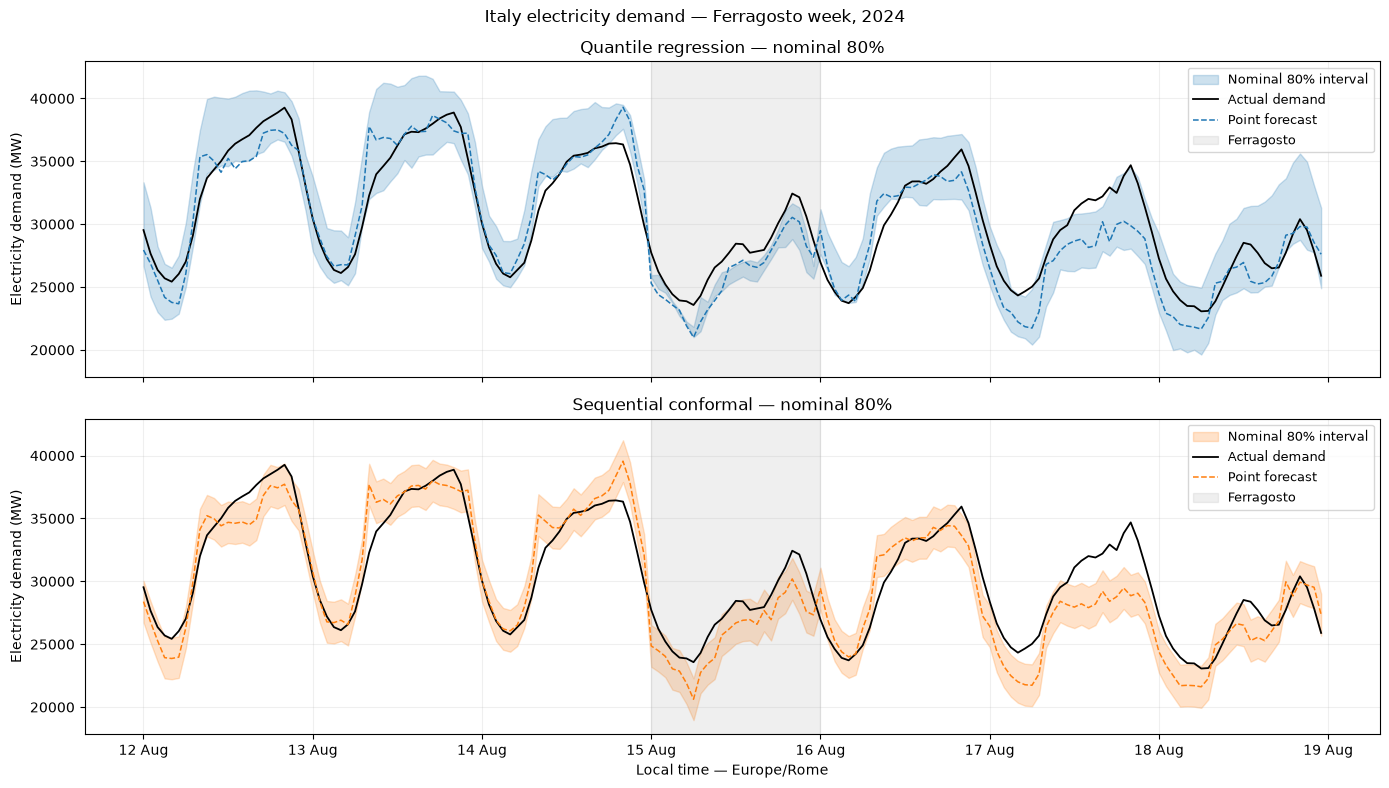

Saved: /Users/marcohlovatskyi/Desktop/Bocconi/ML Projects/Energy/italy-electricity-load-forecasting/notebooks/marco/results/figures/intervals_ferragosto_2024.png


In [45]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from zoneinfo import ZoneInfo

plot_start = pd.Timestamp("2024-08-12", tz=config.LOCAL_TZ)
plot_end = pd.Timestamp("2024-08-19", tz=config.LOCAL_TZ)

plot_methods = [
    (
        quantile_evaluation,
        "Quantile regression — nominal 80%",
        "tab:blue",
    ),
    (
        conformal_intervals,
        "Sequential conformal — nominal 80%",
        "tab:orange",
    ),
]

fig, axes = plt.subplots(
    2, 1,
    figsize=(14, 8),
    sharex=True,
    sharey=True,
)

for ax, (frame, title, color) in zip(axes, plot_methods):
    local_index = frame.index.tz_convert(config.LOCAL_TZ)
    mask = (local_index >= plot_start) & (local_index < plot_end)

    week = frame.loc[mask]
    x = week.index.tz_convert(config.LOCAL_TZ)

    if len(week) != 168:
        raise ValueError("Expected 168 hourly observations for this week.")

    ax.fill_between(
        x,
        week["y_lo"].to_numpy(),
        week["y_hi"].to_numpy(),
        color=color,
        alpha=0.22,
        label="Nominal 80% interval",
    )
    ax.plot(
        x,
        week["y_true"].to_numpy(),
        color="black",
        linewidth=1.3,
        label="Actual demand",
    )
    ax.plot(
        x,
        week["y_pred"].to_numpy(),
        color=color,
        linewidth=1.1,
        linestyle="--",
        label="Point forecast",
    )

    # Highlight Ferragosto in local time.
    ax.axvspan(
        pd.Timestamp("2024-08-15", tz=config.LOCAL_TZ),
        pd.Timestamp("2024-08-16", tz=config.LOCAL_TZ),
        color="grey",
        alpha=0.12,
        label="Ferragosto",
    )

    ax.set_title(title)
    ax.set_ylabel("Electricity demand (MW)")
    ax.grid(alpha=0.2)
    ax.legend(loc="upper right", fontsize=9)

local_timezone = ZoneInfo(config.LOCAL_TZ)
axes[-1].xaxis.set_major_locator(
    mdates.DayLocator(tz=local_timezone)
)
axes[-1].xaxis.set_major_formatter(
    mdates.DateFormatter("%d %b", tz=local_timezone)
)
axes[-1].set_xlabel("Local time — Europe/Rome")

fig.suptitle("Italy electricity demand — Ferragosto week, 2024")
fig.tight_layout()

figures_dir = results_dir / "figures"
figures_dir.mkdir(parents=True, exist_ok=True)

figure_path = figures_dir / "intervals_ferragosto_2024.png"
fig.savefig(figure_path, dpi=180, bbox_inches="tight")

plt.show()
print("Saved:", figure_path)

### Ferragosto-week observations

Both point models underestimate demand during several hours on
15 and 17 August. Some observations exceed the upper interval bounds,
particularly around the 17 August peak for the conformal method.

Quantile interval widths vary across target hours. The implemented
conformal method uses one symmetric radius per forecast day.

This plot illustrates local failures; annual coverage alone does not
describe performance during individual holiday periods.

In [46]:
# Evaluate the plotted week and Ferragosto separately.
calendar_windows = {
    "ferragosto_week": (
        pd.Timestamp("2024-08-12", tz=config.LOCAL_TZ),
        pd.Timestamp("2024-08-19", tz=config.LOCAL_TZ),
    ),
    "ferragosto_day": (
        pd.Timestamp("2024-08-15", tz=config.LOCAL_TZ),
        pd.Timestamp("2024-08-16", tz=config.LOCAL_TZ),
    ),
}

ferragosto_records = []

for model_name, (frame, nominal) in interval_methods.items():
    local_index = frame.index.tz_convert(config.LOCAL_TZ)

    for window_name, (start, end) in calendar_windows.items():
        subset = frame.loc[
            (local_index >= start) & (local_index < end)
        ]

        ferragosto_records.append({
            "period": window_name,
            **summarize_intervals(subset, model_name, nominal),
        })

ferragosto_metrics = pd.DataFrame(ferragosto_records)

display(ferragosto_metrics[[
    "model",
    "period",
    "n",
    "empirical_coverage",
    "mean_width_mw",
    "below_interval_rate",
    "above_interval_rate",
]])

ferragosto_metrics.to_csv(
    results_dir / "interval_coverage_ferragosto.csv",
    index=False,
)

,model,period,n,empirical_coverage,mean_width_mw,below_interval_rate,above_interval_rate
0,lgbm_quantile80_noweather,ferragosto_week,168,0.660714,4446.933633,0.148810,0.190476
1,lgbm_quantile80_noweather,ferragosto_day,24,0.041667,1373.297973,0.000000,0.958333
2,lgbm_conformal80_expanding_noweather,ferragosto_week,168,0.571429,3325.207869,0.113095,0.315476
3,lgbm_conformal80_expanding_noweather,ferragosto_day,24,0.500000,3321.111004,0.000000,0.500000


### Ferragosto results

During 12–18 August, quantile intervals cover 111 of 168 hours (66.07%),
while sequential conformal intervals cover 96 hours (57.14%).

On 15 August alone, coverage falls to 1 of 24 hours (4.17%) for quantile
intervals and 12 of 24 hours (50.00%) for conformal intervals.
All uncovered observations lie above the upper interval bound.

Quantile intervals are particularly narrow on the holiday:
mean width is 1,373 MW, compared with 4,447 MW over the full week.

These results document a specific holiday failure. They do not establish
its cause or imply that either method is uniformly better.

In [47]:
# Select a seven-day summer window using training temperatures only.
hourly_city_mean = weather_for_heatwaves.mean(axis=1)

daily_city_mean = hourly_city_mean.groupby(
    config.local_midnight(hourly_city_mean.index)
).mean()

training_days = config.local_midnight(train.index).unique()

training_daily_temperature = daily_city_mean.loc[
    daily_city_mean.index.isin(training_days)
].copy()

# Require seven consecutive calendar days, all within June–September.
training_daily_temperature.index = (
    training_daily_temperature.index.tz_localize(None)
)
training_daily_temperature = training_daily_temperature.asfreq("D")

summer_daily_temperature = training_daily_temperature.where(
    training_daily_temperature.index.month.isin(config.HEATWAVE_MONTHS)
)

seven_day_temperature = summer_daily_temperature.rolling(
    window=7,
    min_periods=7,
).mean()

if seven_day_temperature.notna().sum() == 0:
    raise ValueError("No complete seven-day training summer window.")

selected_training_end = seven_day_temperature.idxmax()
selected_training_start = selected_training_end - pd.Timedelta(days=6)

summer_plot_start = pd.Timestamp(
    year=2024,
    month=selected_training_start.month,
    day=selected_training_start.day,
    tz=config.LOCAL_TZ,
)
summer_plot_end = summer_plot_start + pd.DateOffset(days=7)

print(
    "Selected training window:",
    selected_training_start.date(),
    "to",
    selected_training_end.date(),
)
print(
    "Training-window mean temperature (°C):",
    round(float(seven_day_temperature.max()), 2),
)
print("Validation plot start:", summer_plot_start)
print("Validation plot end (exclusive):", summer_plot_end)

Selected training window: 2023-08-19 to 2023-08-25
Training-window mean temperature (°C): 30.22
Validation plot start: 2024-08-19 00:00:00+02:00
Validation plot end (exclusive): 2024-08-26 00:00:00+02:00


### Summer window selected using training temperatures

The warmest seven-day June–September window in the training data was
19–25 August 2023, with a six-city mean temperature of 30.22 °C.

Plot the same calendar dates in validation: 19–25 August 2024.
Selection uses training temperatures only, without validation errors.

This is a training-selected summer window, not an identified 2024 heatwave.

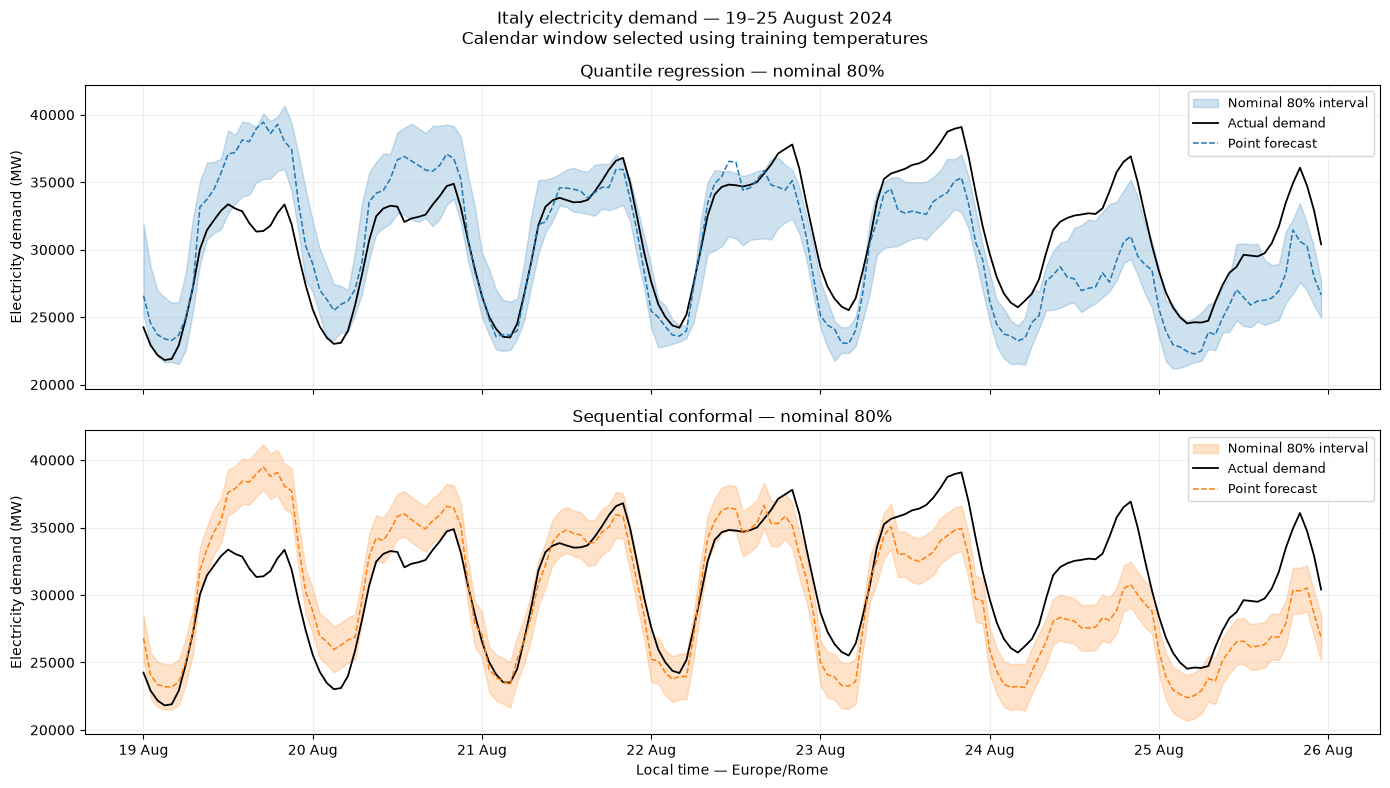

,model,n,empirical_coverage,mean_width_mw,below_interval_rate,above_interval_rate
0,lgbm_quantile80_noweather,168,0.505952,4576.544671,0.107143,0.386905
1,lgbm_conformal80_expanding_noweather,168,0.369048,3377.195575,0.208333,0.422619


Saved: /Users/marcohlovatskyi/Desktop/Bocconi/ML Projects/Energy/italy-electricity-load-forecasting/notebooks/marco/results/figures/intervals_training_selected_summer_window_2024.png


In [48]:
fig, axes = plt.subplots(
    2, 1,
    figsize=(14, 8),
    sharex=True,
    sharey=True,
)

summer_window_records = []

for ax, (frame, title, color) in zip(axes, plot_methods):
    local_index = frame.index.tz_convert(config.LOCAL_TZ)
    mask = (
        (local_index >= summer_plot_start)
        & (local_index < summer_plot_end)
    )

    week = frame.loc[mask]
    x = week.index.tz_convert(config.LOCAL_TZ)

    if len(week) != 168:
        raise ValueError("Expected 168 hourly observations.")

    ax.fill_between(
        x,
        week["y_lo"].to_numpy(),
        week["y_hi"].to_numpy(),
        color=color,
        alpha=0.22,
        label="Nominal 80% interval",
    )
    ax.plot(
        x,
        week["y_true"].to_numpy(),
        color="black",
        linewidth=1.3,
        label="Actual demand",
    )
    ax.plot(
        x,
        week["y_pred"].to_numpy(),
        color=color,
        linewidth=1.1,
        linestyle="--",
        label="Point forecast",
    )

    ax.set_title(title)
    ax.set_ylabel("Electricity demand (MW)")
    ax.grid(alpha=0.2)
    ax.legend(loc="upper right", fontsize=9)

# Use the same evaluation function as in the other tables.
for model_name, (frame, nominal) in interval_methods.items():
    local_index = frame.index.tz_convert(config.LOCAL_TZ)
    week = frame.loc[
        (local_index >= summer_plot_start)
        & (local_index < summer_plot_end)
    ]

    summer_window_records.append({
        "period": "training_selected_summer_window",
        **summarize_intervals(week, model_name, nominal),
    })

axes[-1].xaxis.set_major_locator(
    mdates.DayLocator(tz=local_timezone)
)
axes[-1].xaxis.set_major_formatter(
    mdates.DateFormatter("%d %b", tz=local_timezone)
)
axes[-1].set_xlabel("Local time — Europe/Rome")

fig.suptitle(
    "Italy electricity demand — 19–25 August 2024\n"
    "Calendar window selected using training temperatures"
)
fig.tight_layout()

summer_figure_path = (
    figures_dir / "intervals_training_selected_summer_window_2024.png"
)
fig.savefig(summer_figure_path, dpi=180, bbox_inches="tight")
plt.show()

summer_window_metrics = pd.DataFrame(summer_window_records)
summer_window_metrics.to_csv(
    results_dir / "interval_coverage_training_selected_summer_window.csv",
    index=False,
)

display(summer_window_metrics[[
    "model",
    "n",
    "empirical_coverage",
    "mean_width_mw",
    "below_interval_rate",
    "above_interval_rate",
]])

print("Saved:", summer_figure_path)


## Validation findings and limitations

### Point forecasts

On the 2024 validation period, the no-weather LightGBM model achieves
MAE 1,136.99 MW and RMSE 1,623.18 MW.

The observed-weather model achieves MAE 1,046.46 MW and RMSE
1,524.11 MW. This experiment is labelled "upper bound": observed
target-hour weather is unavailable for an operational day-ahead forecast.

Both LightGBM models outperform the seasonal baselines but do not
outperform the downloaded Terna forecast series. The historical
availability of Terna forecast versions at the required cutoff remains
a separate verification issue.

The forecast-weather experiment remains blocked until the forecast
dataset is available and its coverage has been verified.

### Prediction intervals

For nominal 80% intervals over 8,784 validation hours:

- Quantile regression: coverage 66.35%, mean width 2,723 MW.
- Sequential conformal: coverage 74.92%, mean width 3,189 MW.

Neither method reaches nominal coverage overall. Conformal coverage
is higher overall but is not higher in every season or selected week.

Holiday coverage is particularly low: 35.19% for quantile intervals
and 51.22% for conformal intervals.

On 15 August, coverage is 4.17% and 50.00%, respectively.
During the training-selected calendar window of 19–25 August 2024,
coverage is 50.60% and 36.90%, respectively.

No 2024 days satisfy the shared heatwave definition. Heatwave coverage
is therefore undefined (n = 0). The selected summer plot must not be
interpreted as an identified 2024 heatwave.

### Methodological limitations

The conformal base model reserves October–December 2023 for calibration,
whereas the quantile models use a longer fitting period. This is a
comparison of complete forecasting procedures, not an isolated comparison
of interval-construction methods.

Sequential calibration uses only residuals available at each forecast
cutoff, under the shared two-hour publication-delay assumption.
The base model remains fixed and the calibration history expands.

Temporal dependence means that standard exchangeability-based conformal
coverage guarantees are not assumed. Reported coverage is empirical
and applies to individual hours, not jointly to an entire forecast day.

No 2025 test performance is evaluated in this notebook.